# Dangerous Tornadoes: What Makes a Tornado Cause Casualties?
### Hanna Bingley, Eric Wagner, Linfeng Cheng, Jihyeon Seo

Tornadoes are rated by the damage they cause, but whether a tornado actually hurts or kills people also depends on *who and what is in its path*. This notebook builds a tornado-level dataset from the NOAA Storm Prediction Center (SPC) record, links it to U.S. Census data, and asks which physical and social factors are associated with casualties.

**Research questions**

1. How strongly are a tornado's physical characteristics (EF rating, path length, path width) associated with injuries and fatalities?
2. Holding those characteristics fixed, are **population density** and **mobile home share** (a proxy for housing vulnerability) still associated with casualties?
3. How well can we predict, on a held-out future period, which tornadoes cause casualties, and which features do the models rely on?

**Outcome variable:** `casualty` = 1 if a tornado has at least one reported injury or fatality (`inj + fat > 0`), else 0. Only about 7% of tornadoes have casualties, so we evaluate models with PR-AUC rather than accuracy.

In [1]:
import os
import hashlib
import warnings
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from scipy import stats
from scipy.stats import chi2_contingency, pearsonr, spearmanr
import statsmodels.formula.api as smf

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier


# Project-wide settings
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

sns.set_style("whitegrid")

## 1. Data Processing and Data Cleaning

### 1.1 Input and organize the tornados dataset

In this section we load the raw SPC file, decide which rows and columns belong in the analysis, and produce two tidy tables:

* `tornado_clean.csv`: one row per tornado (whole-track record)
* `tornado_county.csv`: one row per (tornado, county) pair, used later to attach census data


In [2]:
# Import our tornadoes information
tornados_df = pd.read_csv('data/1950-2025_all_tornadoes.csv', low_memory=False)

In [3]:
# Import the file description
desc = pd.read_csv('data/spc_tornado_codebook_up.csv')

In [4]:
# Quick Understanding of our dataset
display(tornados_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74956 entries, 0 to 74955
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   om      74956 non-null  object 
 1   yr      74956 non-null  int64  
 2   mo      74956 non-null  int64  
 3   dy      74956 non-null  int64  
 4   date    74956 non-null  object 
 5   time    74956 non-null  object 
 6   tz      74956 non-null  int64  
 7   st      74956 non-null  object 
 8   stf     74956 non-null  int64  
 9   stn     74956 non-null  int64  
 10  mag     74956 non-null  int64  
 11  inj     74956 non-null  int64  
 12  fat     74956 non-null  int64  
 13  loss    74956 non-null  float64
 14  closs   74956 non-null  float64
 15  slat    74956 non-null  float64
 16  slon    74956 non-null  float64
 17  elat    74956 non-null  float64
 18  elon    74956 non-null  float64
 19  len     74956 non-null  float64
 20  wid     74956 non-null  int64  
 21  ns      74956 non-null  int64  
 22

None

In [5]:
display(tornados_df.describe(include='all'))

,om,yr,mo,dy,date,time,tz,st,stf,stn,...,ns,sn,sg,f1,f2,f3,f4,fc,edat,etime
count,74956,74956.000000,74956.000000,74956.000000,74956,74956,74956.000000,74956,74956.000000,74956.000000,...,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,74956.000000,24880,24880
unique,26698,NaN,NaN,NaN,12998,1438,NaN,53,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3276,1439
top,124,NaN,NaN,NaN,2011-04-27,16:00:00,NaN,TX,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-04-27,17:35:00
freq,67,NaN,NaN,NaN,234,1004,NaN,9681,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,236,74
mean,NaN,1993.987059,5.932134,15.932894,NaN,NaN,3.000881,NaN,29.042705,19.490741,...,1.028123,0.989194,0.999440,103.792972,9.328433,1.863306,0.595576,0.024868,NaN,NaN
std,NaN,20.519378,2.459246,8.784929,NaN,NaN,0.069297,NaN,14.974762,30.282875,...,0.169942,0.103391,0.452654,95.399037,39.662910,17.441124,9.733466,0.155724,NaN,NaN
min,NaN,1950.000000,1.000000,1.000000,NaN,NaN,0.000000,NaN,1.000000,0.000000,...,0.000000,0.000000,-9.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,1977.000000,4.000000,8.000000,NaN,NaN,3.000000,NaN,18.000000,0.000000,...,1.000000,1.000000,1.000000,37.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,NaN,1997.000000,6.000000,16.000000,NaN,NaN,3.000000,NaN,28.000000,7.000000,...,1.000000,1.000000,1.000000,85.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,NaN,2011.000000,7.000000,24.000000,NaN,NaN,3.000000,NaN,42.000000,26.000000,...,1.000000,1.000000,1.000000,135.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN


### 1.2 Data Cleaning

#### 1.2.1 Multiple Tornadoes

A tornado can appear in several rows in this dataset. According to the file description, the number of unique tornadoes can be determined by considering the "ns", "sn", and "sg" variables.

ns: Number of states affected by this tornado (1, 2, 3)  
sn: Whether entire track infomation in this row  
1: complete information  
0: else  
sg: Types of rows  
1: Entire track information  
2: Segments by state  
-9: Additional counties  
According to this information, rows where sg == 1 summarize the entire path of a tornado; therefore, the number of unique tornadoes can be determined by counting the rows where sg == 1.

In [6]:
tornados_df.groupby(["ns", "sn", "sg"])["sg"].count()

ns  sn  sg
0   0   -9        1
1   0   -9      115
    1    1    72788
2   0   -9       23
         1      656
    1    2     1316
3   0   -9        1
         1       14
    1    2       42
Name: sg, dtype: int64

According to the groupby results (all years), there were 72,788 single-state tornadoes (1,1,1), 656 two-state tornadoes (2,0,1), and 14 three-state tornadoes (3,0,1). The rows with sg = 2 are state segments of those multi-state tornadoes, and the rows with sg = -9 only list additional counties.  


Delete rows where the variable 'ns' is 0. (ns must be 1, 2, 3)

In [7]:
tornados_df.drop(tornados_df[tornados_df["ns"] == 0].index, inplace = True)

To conduct a unique tornado analysis, we must drop all rows except those where "sg == 1"; however, doing so would result in the loss of county information.  Since we need to merge this with data such as population figures later, we must create a separate DataFrame that records the counties passed by each individual tornado.

#### 1.2.2 Time period of analysis

Previous study indicates that the number of observed tornadoes increased following the completion of radar installations for tornado detection in 1995. It is necessary to verify this and determine the time period for the dataset to be used in the analysis.

In [8]:
cnt = tornados_df.groupby(["yr"])["sg"].apply(lambda x: x[x == 1].count()).reset_index()

cnt["period"] = cnt["yr"] >= 1995
cnt.groupby("period")["sg"].mean().reset_index()

# before 1995: False / after 1995: True

,period,sg
0,False,759.866667
1,True,1266.580645


The average annual number of tornadoes showed a significant difference between the periods before and after 1995, with 760 and 1,267 tornadoes, respectively. Therefore, we are going to use only the data after 1995.

In [9]:
new_tornados_df = tornados_df[tornados_df["yr"] >= 1995].copy()
new_tornados_df.describe()

,yr,mo,dy,tz,stf,stn,mag,inj,fat,loss,...,len,wid,ns,sn,sg,f1,f2,f3,f4,fc
count,40205.000000,40205.000000,40205.000000,40205.0,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,4.020500e+04,...,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.0
mean,2010.266982,5.904390,16.162045,3.0,28.078672,13.189578,0.223156,0.822286,0.066634,9.550544e+05,...,3.439134,144.028131,1.034175,0.987788,1.009178,100.870688,9.720308,1.609004,0.451113,0.0
std,9.057967,2.584289,8.860605,0.0,14.927819,27.195685,2.011260,12.925578,1.285258,2.895273e+07,...,6.529076,245.768468,0.186544,0.109834,0.389061,90.890861,39.841133,16.410123,8.367417,0.0
min,1995.000000,1.000000,1.000000,3.0,1.000000,0.000000,-9.000000,0.000000,0.000000,0.000000e+00,...,0.000000,0.000000,1.000000,0.000000,-9.000000,0.000000,0.000000,0.000000,0.000000,0.0
25%,2003.000000,4.000000,8.000000,3.0,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,0.280000,30.000000,1.000000,1.000000,1.000000,39.000000,0.000000,0.000000,0.000000,0.0
50%,2010.000000,5.000000,16.000000,3.0,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,...,1.120000,50.000000,1.000000,1.000000,1.000000,83.000000,0.000000,0.000000,0.000000,0.0
75%,2018.000000,7.000000,24.000000,3.0,40.000000,14.000000,1.000000,0.000000,0.000000,1.000000e+04,...,4.000000,150.000000,1.000000,1.000000,1.000000,133.000000,0.000000,0.000000,0.000000,0.0
max,2025.000000,12.000000,31.000000,3.0,78.000000,232.000000,5.000000,1500.000000,158.000000,2.800102e+09,...,168.530000,4576.000000,3.000000,1.000000,2.000000,810.000000,820.000000,710.000000,437.000000,0.0


#### 1.2.3 Remove unncessary columns

"tz" (time zone) are all 3, so drop this column


"fc" (f-scale changed flag) are all 0, so drop this column


"edat" and "etime" appear only in data after 2007, so drop these columns


"stn" is number of this tornado in this state in this year, but it discontinued in 2008. We drop this column.

In [10]:
new_tornados_df = new_tornados_df.drop(columns=["tz", "fc", "edat", "etime", "stn"])
new_tornados_df.describe()

,yr,mo,dy,stf,mag,inj,fat,loss,closs,slat,...,elon,len,wid,ns,sn,sg,f1,f2,f3,f4
count,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,4.020500e+04,4.020500e+04,40205.000000,...,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000,40205.000000
mean,2010.266982,5.904390,16.162045,28.078672,0.223156,0.822286,0.066634,9.550544e+05,6.035615e+03,37.110849,...,-89.740908,3.439134,144.028131,1.034175,0.987788,1.009178,100.870688,9.720308,1.609004,0.451113
std,9.057967,2.584289,8.860605,14.927819,2.011260,12.925578,1.285258,2.895273e+07,2.108153e+05,5.117238,...,16.856074,6.529076,245.768468,0.186544,0.109834,0.389061,90.890861,39.841133,16.410123,8.367417
min,1995.000000,1.000000,1.000000,1.000000,-9.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,...,-163.530000,0.000000,0.000000,1.000000,0.000000,-9.000000,0.000000,0.000000,0.000000,0.000000
25%,2003.000000,4.000000,8.000000,17.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,33.334900,...,-97.584200,0.280000,30.000000,1.000000,1.000000,1.000000,39.000000,0.000000,0.000000,0.000000
50%,2010.000000,5.000000,16.000000,28.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,37.006500,...,-91.930000,1.120000,50.000000,1.000000,1.000000,1.000000,83.000000,0.000000,0.000000,0.000000
75%,2018.000000,7.000000,24.000000,40.000000,1.000000,0.000000,0.000000,1.000000e+04,0.000000e+00,40.763200,...,-85.913500,4.000000,150.000000,1.000000,1.000000,1.000000,133.000000,0.000000,0.000000,0.000000
max,2025.000000,12.000000,31.000000,78.000000,5.000000,1500.000000,158.000000,2.800102e+09,2.352000e+07,61.130000,...,0.000000,168.530000,4576.000000,3.000000,1.000000,2.000000,810.000000,820.000000,710.000000,437.000000


#### 1.2.4 Length and width

In [11]:
len_0 = new_tornados_df[(new_tornados_df["len"] == 0)]
display(len(len_0))
wid_0 = new_tornados_df[(new_tornados_df["wid"] == 0)]
display(len(wid_0))

175

530

In [12]:
display(len_0.groupby(["mag"])["mag"].count())
display(wid_0.groupby(["mag"])["mag"].count())

mag
0    169
1      5
4      1
Name: mag, dtype: int64

mag
0    429
1     73
2     17
3     10
4      1
Name: mag, dtype: int64

There are 530 rows with a width of 0 and 175 with a length of 0. Considering the magnitude values ​​as well, these appear to be missing values.

#### 1.2.5 Unknown Magnitude

Unknown magnitude (mag == -9)

Magnitude is crucial in the analysis; we must determine whether to include rows with unknown magnitudes.

In [13]:
new_tornados_df.groupby("mag")["mag"].count()

mag
-9     1560
 0    21604
 1    12475
 2     3399
 3      946
 4      204
 5       17
Name: mag, dtype: int64

Since the number of rows have unknown magnitude are 1,560, we cannot drop these rows. 


Check the average length and width for each grade

In [14]:
display(new_tornados_df.groupby("mag")["len"].mean())
display(new_tornados_df.groupby("mag")["wid"].mean())

mag
-9     1.246192
 0     1.373635
 1     4.214658
 2     8.890850
 3    17.863964
 4    30.655490
 5    41.143529
Name: len, dtype: float64

mag
-9      47.955769
 0      58.164738
 1     184.177555
 2     373.944984
 3     689.079281
 4    1037.725490
 5    1590.000000
Name: wid, dtype: float64

The average length and width of the "EF unknown" tornado were smaller than those of the EF0 tornado. This suggests that the "EF unknown" tornadoes were likely too small for an accurate damage rating to be assigned.


#### 1.2.6 "Loss" and "Closs"

According to the file documentation, loss and closs changes units over time: category codes in 1995, millions of dollars in 1996–2006, and dollars from 2007. A value of 0 does not mean no loss. These are good variables to refer to along with casualty analysis, but if 0 is not an accurate value, there is a possibility of incorrect analysis.


Therefore, these two variables will be excluded from the analysis.

In [15]:
new_tornados_df = new_tornados_df.drop(columns=["loss", "closs"])

#### 1.2.7 Contigous United States Data

We keep only tornadoes in the contiguous United States (CONUS) and exclude those in Alaska, Hawaii, Puerto Rico, and the U.S. Virgin Islands.

In [16]:
new_tornados_df = new_tornados_df[~new_tornados_df["st"].isin(["AK", "HI", "PR", "VI"])].copy()

#### 1.2.8 Create a Tornado-County linkage DataFrame

Each row is one (tornado, county) pair, so a tornado that crossed three counties has three rows.


Counties of multi-state tornadoes are only in the state-segment rows (sg = 2, -9), so we link those rows to their whole-track row before keeping sg == 1.
To link the tornado and county data, we need to find a key that identifies the same tornado. According to the file documentation, it appears possible to create this key by combining "om" and "yr".


In the case of "om," the format changed starting in 2007, and the file documentation states that segments of a tornado crossing state borders and/or spanning more than four counties share the same "om" (see ns/sn/sg).


Accordingly, we first select the rows where sg == 1 and check whether the combination of "om" and "yr" is unique.

In [17]:
# wdf: whole route df
wdf = new_tornados_df[new_tornados_df["sg"] == 1].copy()
wdf["tor_id"] = wdf.index
wdf["idx"] = wdf["yr"].astype(str) + wdf["om"].astype(str)
wdf["idx"].is_unique

False

Since "idx" is not unique, we have to find duplicated rows.

In [18]:
wdf[wdf.duplicated(["idx"], keep=False)].sort_values(["idx"])

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid,ns,sn,sg,f1,f2,f3,f4,tor_id,idx
35175,9999,1995,5,13,1995-05-13,15:18:00,IL,17,4,7,...,1000,1,1,1,67,71,187,0,35175,19959999
35519,9999,1995,5,9,1995-05-09,16:17:00,IA,19,1,0,...,50,1,1,1,163,0,0,0,35519,19959999
42528,56,2001,3,15,2001-03-15,03:30:00,FL,12,2,21,...,350,1,1,1,133,63,0,0,42528,200156
42529,56,2001,3,15,2001-03-15,03:40:00,FL,12,2,0,...,300,1,1,1,63,0,0,0,42529,200156
43767,506,2002,4,11,2002-04-11,16:19:00,KS,20,0,0,...,220,1,1,1,155,0,0,0,43767,2002506
43768,506,2002,4,11,2002-04-11,16:35:00,KS,20,0,0,...,110,1,1,1,95,0,0,0,43768,2002506


Three pairs share the same idx but have different dates, times, or counties, so they are different tornadoes. All six are single-state tornadoes with no segment rows.
We keep all of them and modify their idx.

In [19]:
wdf.loc[35519, "idx"] = "19959999-2"
wdf.loc[42529, "idx"] = "200156-2"
wdf.loc[43768, "idx"] = "2002506-2"
wdf["idx"].is_unique

True

Now, we merge the whole dataframe (sg==1) with the segment dataframe (sg != 1).

In [20]:
# sdf: segment df
sdf = new_tornados_df[new_tornados_df["sg"] != 1].copy()
sdf["idx"] = sdf["yr"].astype(str) + sdf["om"].astype(str)
print(len(sdf))
m_df = sdf.merge(wdf,
                 on = "idx", how = "left",
                 suffixes=("", "_whole"),
                 indicator = True,
                 validate="many_to_one")
m_df["_merge"].value_counts()

941


_merge
left_only     718
both          223
right_only      0
Name: count, dtype: int64

Out of a total of 941 items, 718 failed to find a match. This shows that a key cannot be created simply by merging "yr" and "om". We need to examine a few of the "left-only" rows to determine the proper way to make the key.

In [21]:
display(m_df[m_df["yr"] == 1997].head(5))
display(m_df[m_df["yr"] == 2020].head(5))

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid_whole,ns_whole,sn_whole,sg_whole,f1_whole,f2_whole,f3_whole,f4_whole,tor_id,_merge
24,558,1997,10,25,1997-10-25,16:10:00,MS,28,1,7,...,300.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37234.0,both
25,558,1997,10,25,1997-10-25,17:10:00,AL,1,1,0,...,300.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37234.0,both
26,454,1997,6,17,1997-06-17,18:13:00,TN,47,1,0,...,30.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37930.0,both
27,454,1997,6,17,1997-06-17,18:23:00,KY,21,1,2,...,30.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,37930.0,both
28,903,1997,7,3,1997-07-03,17:20:00,NY,36,2,0,...,100.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,38190.0,both


,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid_whole,ns_whole,sn_whole,sg_whole,f1_whole,f2_whole,f3_whole,f4_whole,tor_id,_merge
642,2001110333-03,2020,1,11,2020-01-11,03:33:00,AR,5,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
643,2001110333-01,2020,1,11,2020-01-11,03:44:00,MS,28,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
644,2003241627-02,2020,3,24,2020-03-24,16:27:00,MS,28,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
645,2003241627-03,2020,3,24,2020-03-24,16:39:00,AL,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only
646,2003281918-02,2020,3,28,2020-03-28,19:18:00,KY,21,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,left_only


Comparing the results of 1997 and 2020, all connections were successful in 1997, but none were connected in 2020. This appears to be related to the format change of "om" in 2007. Connection status must be checked by year.

In [22]:
# not connected
g = m_df[m_df["_merge"] == "left_only"]["yr"].reset_index()
display(g.groupby("yr").count().T)

# after 2007 - all results
k = m_df[m_df["yr"] > 2006]["yr"].reset_index()
display(k.groupby("yr").count().T)

yr,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
index,13,46,23,34,74,17,32,21,31,14,45,19,50,33,50,26,40,82,68


yr,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
index,13,46,23,34,74,17,32,21,31,14,45,19,50,33,50,26,40,82,68


Based on these two results, we can confirm that none of the rows after 2007 are connected. We need to verify the format of "om".

In [23]:
df_2007 = new_tornados_df[(new_tornados_df["yr"] == 2007) & (new_tornados_df["ns"] == 2)]
df_2007 = df_2007.sort_values("om")
df_2007.head(6)

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,elon,len,wid,ns,sn,sg,f1,f2,f3,f4
50415,0703011352-01,2007,3,1,2007-03-01,13:52:00,AL,1,1,2,...,-85.0396,30.84,150,2,0,1,0,0,0,0
50416,0703011352-02,2007,3,1,2007-03-01,13:52:00,AL,1,1,2,...,-85.0984,22.99,150,2,1,2,67,0,0,0
50418,0703011352-03,2007,3,1,2007-03-01,14:24:00,GA,13,0,0,...,-85.0396,7.85,100,2,1,2,61,239,0,0
50430,0703011727-01,2007,3,1,2007-03-01,17:27:00,AL,1,2,1,...,-84.8715,11.74,300,2,0,1,0,81,0,0
50431,0703011727-02,2007,3,1,2007-03-01,17:27:00,AL,1,1,0,...,-85.0066,2.31,100,2,1,2,113,81,0,0
50433,0703011727-03,2007,3,1,2007-03-01,17:31:00,GA,13,2,1,...,-84.8715,9.43,300,2,1,2,215,0,0,0


The results above represent two tornadoes that affected two states in 2007. Looking at the 'om' field, the first ten characters are identical, while '01', '02', and '03' have been appended to distinguish between them.


Now we can make the key with the first 10 digit of "om" for the data after 2007. We also have to check the uniqueness of these keys before using.

In [24]:
wdf["idx"] = wdf["yr"].astype(str) + wdf["om"].astype(str).where(wdf["yr"] < 2007, wdf["om"].str[:10])
wdf.loc[35519, "idx"] = "19959999-2"
wdf.loc[42529, "idx"] = "200156-2"
wdf.loc[43768, "idx"] = "2002506-2"
wdf["idx"].is_unique

False

The keys are not unique either. We need to check for duplicate data.

In [25]:
dup = wdf[wdf.duplicated(["idx"], keep=False)].sort_values(["idx"])
display(dup.head(6))
display(dup["idx"].nunique())

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid,ns,sn,sg,f1,f2,f3,f4,tor_id,idx
50295,0703241735-01,2007,3,24,2007-03-24,17:35:00,CO,8,0,0,...,50,1,1,1,115,0,0,0,50295,20070703241735
50296,0703241735-02,2007,3,24,2007-03-24,17:35:00,NE,31,0,0,...,10,1,1,1,101,0,0,0,50296,20070703241735
50316,0703281703-02,2007,3,28,2007-03-28,17:03:00,TX,48,0,0,...,220,1,1,1,45,0,0,0,50316,20070703281703
50315,0703281703-01,2007,3,28,2007-03-28,17:03:00,TX,48,0,0,...,50,1,1,1,153,0,0,0,50315,20070703281703
50323,0703281805-01,2007,3,28,2007-03-28,18:05:00,TX,48,0,0,...,200,1,1,1,129,0,0,0,50323,20070703281805
50324,0703281805-02,2007,3,28,2007-03-28,18:05:00,KS,20,0,0,...,25,1,1,1,39,0,0,0,50324,20070703281805


619

-01 and -02 are used to distinguish between tornadoes that occurred at the same time, and also to distinguish between state sections of the same tornado. Since there are two ways for generating "om", duplication occurs.


However, tornadoes that passed through only a single state are irrelevant to the merging process, so we can disregard them; we only need to check the duplicate rows that contain segment information.

In [26]:
# making the same key in segment dataframe
sdf["idx"] = sdf["yr"].astype(str) + sdf["om"].astype(str).where(sdf["yr"] < 2007, sdf["om"].str[:10])

# check the duplicated idx from segment dataframe
dup_seg = dup[dup["idx"].isin(sdf["idx"])]
display(dup_seg["idx"].nunique())
display(dup_seg.head(5))

23

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,wid,ns,sn,sg,f1,f2,f3,f4,tor_id,idx
51473,0802051732-02,2008,2,5,2008-02-05,17:32:00,MS,28,2,13,...,440,2,0,1,0,0,0,0,51473,20080802051732
51472,0802051732-01,2008,2,5,2008-02-05,17:32:00,TN,47,1,0,...,50,1,1,1,167,0,0,0,51472,20080802051732
52995,0910291413-02,2009,10,29,2009-10-29,14:13:00,AR,5,1,0,...,1050,1,1,1,103,13,103,13,52995,20090910291413
52994,0910291413-01,2009,10,29,2009-10-29,14:13:00,AR,5,1,0,...,75,1,1,1,139,0,0,0,52994,20090910291413
54783,1005231952-01,2010,5,23,2010-05-23,19:52:00,KS,20,0,0,...,10,1,1,1,181,0,0,0,54783,20101005231952


This result shows the duplicate idx pairs within the sdf dataframe that need to be connected.


In 20 of the 23 cases, one tornado has ns = 1 and the other has ns = 2, and the segment rows (ns = 2) belong to the second. Adding ns to the key resolves these.


The 3 cases (idx == 20090910291413, 20111104251748, 20111104270129, 6 rows) are ambiguous to connect which rows in the segment dataframe. We can simply check these rows in the segment dataframe.


In [27]:
display(sdf[sdf["idx"].isin(["20090910291413", "20111104251748", "20111104270129"])])

,om,yr,mo,dy,date,time,st,stf,mag,inj,...,len,wid,ns,sn,sg,f1,f2,f3,f4,idx
52996,0910291413-03,2009,10,29,2009-10-29,14:13:00,AR,5,0,0,...,0.0,0,1,0,-9,103,0,0,0,20090910291413
56112,1104251748-03,2011,4,25,2011-04-25,17:48:00,AR,5,0,0,...,0.0,0,1,0,-9,145,0,0,0,20111104251748
56218,1104270129-03,2011,4,27,2011-04-27,01:29:00,MS,28,0,0,...,0.0,0,1,0,-9,95,0,0,0,20111104270129


These rows are additional county rows(sg = -9), containing information for a county. There is a value only in f1.


If we delete these rows(and we lose only one county information for these 3 tornadoes), the duplication issue will not occur.

In [28]:
sdf = sdf[~sdf["idx"].isin(["20090910291413", "20111104251748", "20111104270129"])].copy()

Finally, we merge wdf with sdf on key "idx" and "ns".

In [29]:
display(sdf.shape)

m_df = sdf.merge(wdf,
                 on = ["idx", "ns"], how = "left",
                 suffixes=("", "_whole"),
                 indicator = True,)
m_df["_merge"].value_counts()

(938, 25)

_merge
both          938
left_only       0
right_only      0
Name: count, dtype: int64

Since the number of rows in "sdf" and "m_df" is the same, we can see that the merge was performed correctly. 


Now we will combine "wdf" and "m_df" to get county information for every tornado.

In [30]:
links = pd.concat([
    wdf[["tor_id", "stf", "f1", "f2", "f3", "f4"]],
    m_df[["tor_id", "stf", "f1", "f2", "f3", "f4"]]
], ignore_index=True)

links

,tor_id,stf,f1,f2,f3,f4
0,34750,51,153,0,0,0
1,34751,24,3,0,0,0
2,34752,24,13,0,0,0
3,34753,12,99,0,0,0
4,34754,24,21,0,0,0
...,...,...,...,...,...,...
40152,74737,48,111,0,0,0
40153,74752,13,105,0,0,0
40154,74752,45,65,0,0,0
40155,74889,38,35,0,0,0


To link additional data later, a dataframe is created in which each Tornado ID is associated with a single county.

In [31]:
# melt
tc = links.melt(id_vars=["tor_id", "stf"],
                 value_vars=["f1", "f2", "f3", "f4"],
                value_name="county")
# drop rows that county code == 0
tc = tc[tc["county"] > 0].copy()

tc["fips"] = (tc["stf"].astype(str).str.zfill(2) +
              tc["county"].astype(str).str.zfill(3))
tc.info()
tc.duplicated(["tor_id", "fips"]).sum()

<class 'pandas.core.frame.DataFrame'>
Index: 44262 entries, 0 to 160571
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   tor_id    44262 non-null  int64 
 1   stf       44262 non-null  int64 
 2   variable  44262 non-null  object
 3   county    44262 non-null  int64 
 4   fips      44262 non-null  object
dtypes: int64(3), object(2)
memory usage: 2.0+ MB


np.int64(282)

Some tornadoes list the same county more than once, for example when the path crosses a county line and comes back. Since we only need the set of counties each tornado affected, we keep each tornado–county pair once (282 repeated pairs will be deleted).

In [32]:
tor_county = tc[["tor_id", "fips"]].drop_duplicates().reset_index(drop=True)
tor_county.head(5)

,tor_id,fips
0,34750,51153
1,34751,24003
2,34752,24013
3,34753,12099
4,34754,24021


#### 1.2.8 Create a final dataframe for analysis

Regarding latitude and longtitude information, the starting information(slat, slon) is fine, but ending information (elat, elon) includes 0. It appears that these are missing values.


We think that the ending information is not crucial in our analysis, so drop these columns.

In [33]:
wdf = wdf.drop(columns=["elat", "elon"])
wdf.describe()

,yr,mo,dy,stf,mag,inj,fat,slat,slon,len,wid,ns,sn,sg,f1,f2,f3,f4,tor_id
count,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000,39219.0,39219.000000,39219.000000,39219.000000,39219.000000,39219.000000
mean,2010.191055,5.910605,16.178128,28.106683,0.202376,0.747597,0.056758,37.178855,-92.220885,3.314210,138.992478,1.011423,0.988806,1.0,101.092991,9.406895,1.467911,0.401948,54756.996328
std,9.057915,2.576439,8.850786,14.877674,2.015676,12.477322,1.176066,4.929441,8.383494,6.215246,236.639636,0.108406,0.105207,0.0,91.299203,39.061651,15.629801,8.057040,11606.919963
min,1995.000000,1.000000,1.000000,1.000000,-9.000000,0.000000,0.000000,24.544000,-124.468200,0.000000,0.000000,1.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,34750.000000
25%,2003.000000,4.000000,8.000000,17.000000,0.000000,0.000000,0.000000,33.350000,-97.837050,0.260000,30.000000,1.000000,1.000000,1.0,39.000000,0.000000,0.000000,0.000000,44687.500000
50%,2010.000000,5.000000,16.000000,28.000000,0.000000,0.000000,0.000000,37.050000,-92.438800,1.070000,50.000000,1.000000,1.000000,1.0,83.000000,0.000000,0.000000,0.000000,54715.000000
75%,2018.000000,7.000000,24.000000,40.000000,1.000000,0.000000,0.000000,40.798050,-86.504050,3.880000,150.000000,1.000000,1.000000,1.0,133.000000,0.000000,0.000000,0.000000,64790.500000
max,2025.000000,12.000000,31.000000,56.000000,5.000000,1500.000000,158.000000,49.330000,-67.807000,168.530000,4576.000000,3.000000,1.000000,1.0,810.000000,820.000000,710.000000,437.000000,74955.000000


Apply the items checked earlier to the wdf:

Map magnitude information (EF: -9 -> EFU, 0 -> EF0, 1 -> EF1 ...), and replace mag == -9 with Nan so that "mag" can be used as a number (EFU is kept in "rating")
Make a column for flagging len or wid == 0 (should be excluded for analysis when using tornadoes' length and width), and replace len/wid of 0 with NaN
Drop unnecessary columns (om, idx, county information, sn, sg)

In [34]:
# mapping magnitude information

wdf["rating"] = wdf["mag"].map({-9: "EFU", 0: "EF0", 1: "EF1", 2: "EF2",
                                    3: "EF3", 4: "EF4", 5: "EF5"})
wdf["mag"] = wdf["mag"].replace(-9, np.nan)

# flagging
wdf["size_flag"] = np.select(
    [(wdf["len"] == 0) & (wdf["wid"] == 0),
     wdf["len"] == 0,
     wdf["wid"] == 0],
    ["both_zero", "len_zero", "wid_zero"],
    default="ok"
    )
wdf[["len", "wid"]] = wdf[["len", "wid"]].where(wdf[["len", "wid"]] > 0)

# drop unnecessary columns
wdf = wdf.drop(columns=["om", "idx", "sn", "sg", "f1", "f2", "f3", "f4"])

wdf.info()


<class 'pandas.core.frame.DataFrame'>
Index: 39219 entries, 34750 to 74955
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   yr         39219 non-null  int64  
 1   mo         39219 non-null  int64  
 2   dy         39219 non-null  int64  
 3   date       39219 non-null  object 
 4   time       39219 non-null  object 
 5   st         39219 non-null  object 
 6   stf        39219 non-null  int64  
 7   mag        37673 non-null  float64
 8   inj        39219 non-null  int64  
 9   fat        39219 non-null  int64  
 10  slat       39219 non-null  float64
 11  slon       39219 non-null  float64
 12  len        39100 non-null  float64
 13  wid        38752 non-null  float64
 14  ns         39219 non-null  int64  
 15  tor_id     39219 non-null  int64  
 16  rating     39219 non-null  object 
 17  size_flag  39219 non-null  object 
dtypes: float64(5), int64(8), object(5)
memory usage: 6.7+ MB


Convert "date" and "time" to python datetime type, for time-based analysis.

In [35]:
wdf["datetime"] = pd.to_datetime(wdf["date"] + " " + wdf["time"])

In [36]:
# remove redundant columns
wdf = wdf.drop(columns=['yr', 'mo', 'dy', 'date', 'time'])

In [37]:
# Make a CSV file
wdf.to_csv("data/tornado_clean.csv", index=False)
tor_county.to_csv("data/tornado_county.csv", index=False)

## 2. Linking Census Data

To study whether *exposure* (how many people live where a tornado strikes) and *vulnerability* (how many homes are mobile homes) matter, we attach county-level census data to each tornado.


In [38]:
CENSUS_KEY = os.environ.get("CENSUS_KEY")
if CENSUS_KEY is None:
    try:
        from google.colab import userdata
        CENSUS_KEY = userdata.get("CENSUS_KEY")
    except Exception:
        CENSUS_KEY = None

def get_census(url, vars_):
    """Download one county-level table from the Census API."""
    params = {"get": vars_, "for": "county:*"}
    if CENSUS_KEY:
        params["key"] = CENSUS_KEY
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    js = r.json()
    return pd.DataFrame(js[1:], columns=js[0])

def build_census_table():
    """2000 Census + ACS 5-year (2009-2024): population, housing units, mobile homes."""
    frames = []
    for y in range(2009, 2025):
        d = get_census(f"https://api.census.gov/data/{y}/acs/acs5",
                       "B01003_001E,B25024_001E,B25024_010E")
        d["census_yr"] = y
        frames.append(d)
        print(y, len(d))
    p = get_census("https://api.census.gov/data/2000/dec/sf1", "P001001")
    h = get_census("https://api.census.gov/data/2000/dec/sf3", "H030001,H030010")
    c2000 = (p.merge(h, on=["state", "county"])
              .rename(columns={"P001001": "B01003_001E",
                               "H030001": "B25024_001E",
                               "H030010": "B25024_010E"}))
    c2000["census_yr"] = 2000

    out = pd.concat([c2000] + frames, ignore_index=True)
    out["fips"] = out["state"] + out["county"]
    out = out.rename(columns={"B01003_001E": "pop", "B25024_001E": "housing",
                              "B25024_010E": "mobile"})
    out = out[["census_yr", "fips", "pop", "housing", "mobile"]]
    out[["pop", "housing", "mobile"]] = out[["pop", "housing", "mobile"]].apply(pd.to_numeric)
    return out[out["fips"].str[:2] != "72"]          

census_path = DATA_DIR / "county_census.csv"
if census_path.exists():
    census = pd.read_csv(census_path, dtype={"fips": str})
    print("Loaded cached census table:", census.shape)
else:
    census = build_census_table()
    census.to_csv(census_path, index=False)
    print("Downloaded and cached census table:", census.shape)

Loaded cached census table: (53426, 5)


In [39]:
# County land area in square miles
gz = pd.read_csv(DATA_DIR / "2012_Gaz_counties_national.txt", sep="\t", dtype={"GEOID": str})
gz.columns = gz.columns.str.strip()          
gz = gz.rename(columns={"GEOID": "fips", "ALAND_SQMI": "land_sqmi"})[["fips", "land_sqmi"]]

### 2.1 County code changes

Some counties changed codes over time. We map old codes to current ones using the Census Bureau's Substantial Changes to Counties and County Equivalent Entities: 1970-Present:

* Dade County, FL (12025) was renamed Miami-Dade County (12086) on July 22, 1997.
* Shannon County, SD (46113) became Oglala Lakota County (46102) on May 1, 2015.
* Bedford (independent) city, VA (51515) became a town and was added to Bedford County (51019) on July 1, 2013.

Connecticut: from the 2022 ACS onward, Connecticut reports its nine planning regions (codes 09110-09190) instead of its eight counties (09001-09015), but the tornado file still uses the old county codes. For Connecticut tornadoes we therefore use 2021 ACS data (the last year with the old county codes) for any tornado in 2022 or later.

In [40]:
# Reload the cleaned files so this section is self-contained
tor_clean = pd.read_csv(DATA_DIR / "tornado_clean.csv", parse_dates=["datetime"])
tor_county = pd.read_csv(DATA_DIR / "tornado_county.csv", dtype={"fips": str})
tor_clean["yr"] = tor_clean["datetime"].dt.year

# Harmonize county codes 
fix = {"12025": "12086",   # Dade -> Miami-Dade
       "46113": "46102",   # Shannon -> Oglala Lakota
       "51515": "51019"}   # Bedford city -> Bedford County
census["fips"] = census["fips"].replace(fix)
census = census.groupby(["census_yr", "fips"], as_index=False)[["pop", "housing", "mobile"]].sum()
gz["fips"] = gz["fips"].replace(fix)
gz = gz.groupby("fips", as_index=False)["land_sqmi"].sum()

# Attach the tornado's year to every (tornado, county) pair
tc = tor_county.merge(tor_clean[["tor_id", "yr"]], on="tor_id", how="left", validate="many_to_one")
tc["census_yr"] = np.select([tc["yr"] <= 2008, tc["yr"] >= 2025], [2000, 2024], default=tc["yr"])

# Connecticut: use 2021 ACS (old county codes) for 2022+
ct = tc["fips"].str.startswith("09") & (tc["census_yr"] >= 2022)
tc.loc[ct, "census_yr"] = 2021

# Apply county-code fixes, then keep each tornado-county pair once
tc["fips"] = tc["fips"].replace(fix)
n_before = len(tc)
tc = tc.drop_duplicates(["tor_id", "fips"])
print(f"Duplicate tornado-county pairs created by code fixes: {n_before - len(tc)}")

# Merge census + area
tcx = tc.merge(census, on=["census_yr", "fips"], how="left", validate="many_to_one", indicator=True)
print(tcx["_merge"].value_counts())
tcx = tcx.merge(gz, on="fips", how="left", validate="many_to_one")
print("Missing land area:", tcx["land_sqmi"].isna().sum())

# Inspect pairs that did not match any census row
display(tcx[tcx["_merge"] == "left_only"][["tor_id", "yr", "fips"]])

Duplicate tornado-county pairs created by code fixes: 0
_merge
both          43978
left_only         2
right_only        0
Name: count, dtype: int64
Missing land area: 2


,tor_id,yr,fips
1947,36728,1996,42159
39728,35195,1995,21022


Two tornado-county pairs have no census match. Their county codes do not exist, so they look like data-entry errors. Both tornadoes also pass through other, valid counties, so we drop only these two pairs rather than the tornadoes.

In [41]:
tcx = tcx[tcx["_merge"] == "both"].drop(columns="_merge")

# Aggregate to one row per tornado: sum over every county it touched
agg = tcx.groupby("tor_id").agg(pop=("pop", "sum"), housing=("housing", "sum"),
                                mobile=("mobile", "sum"), land_sqmi=("land_sqmi", "sum"))
agg["pop_density"] = agg["pop"] / agg["land_sqmi"]            
agg["mobile_pct"] = 100 * agg["mobile"] / agg["housing"]      

tor_census = tor_clean.merge(agg.reset_index(), on="tor_id", how="left", validate="one_to_one")

print(tor_census[["pop_density", "mobile_pct"]].describe().round(2))
print("Tornadoes without census data:", tor_census["pop_density"].isna().sum())
tor_census.to_csv(DATA_DIR / "tornado_census.csv", index=False)

       pop_density  mobile_pct
count     39219.00    39219.00
mean        177.31       12.85
std         590.54        8.94
min           0.10        0.00
25%          17.51        5.68
50%          45.86       10.93
75%         128.97       18.34
max       34836.14       59.23
Tornadoes without census data: 0


## 3. Exploratory Data Analysis

In this section we first look at the physical characteristics of tornadoes (rating, length, width, number of states), then at the census features and regional differences.

### 3.1 Physical characteristics

Here we check for outliers, the shape of each variable, and how the variables relate to injuries and fatalities. We use tornado_clean.csv, which has one row per tornado.

In [42]:
tornados_df = pd.read_csv('data/tornado_clean.csv')
county_df = pd.read_csv('data/tornado_county.csv')

#### Are there outliers?

In the previous section, we have cleaned and merged our files in order to create tornado_clean.csv and tornado_county.csv. In this section, I am going to observe if there are any outliers in the dataset.

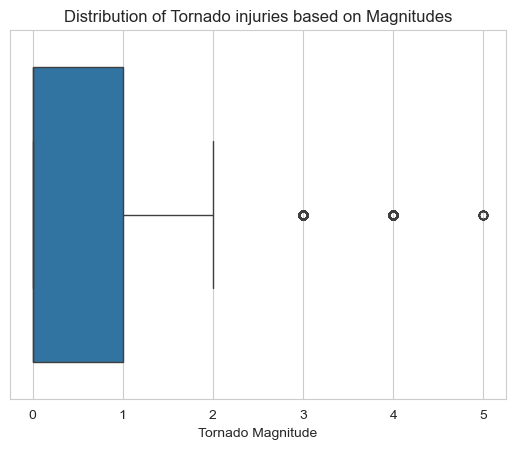

In [43]:
# Looking at the distribution of magnitude of tornados
sns.set_style("whitegrid")
sns.boxplot(x=tornados_df['mag'])

plt.xlabel("Tornado Magnitude")
plt.title("Distribution of Tornado injuries based on Magnitudes")

plt.show()

Based on his boxplot, we can see the median ot tornado magnitudes are 0 and 75% of all recorded tornados are rated 1 or weaker. Since the upper whisker extends to 2, we can see this is the upper boundary for expected tornados. We have 3 invidual tornados are 3, 4, and 5. We can see these are rare events and a majority of tornados are not this extreme.

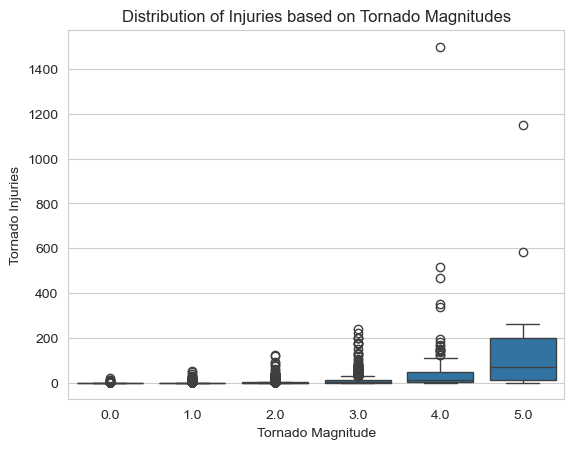

In [44]:
# Look at the distribution of injuries based on tornado magnitudes
sns.set_style("whitegrid")
sns.boxplot(x=tornados_df['mag'], y=tornados_df['inj'])

plt.xlabel("Tornado Magnitude")
plt.ylabel("Tornado Injuries")
plt.title("Distribution of Injuries based on Tornado Magnitudes")

plt.show()

Based on the box and whisker plot above, we can see the spread of tornado's injuries grouped by the tornado magnitude. We can see a clear correlation between tornado magnitude and the spread of injuries. Low magnitude tornados (0.0 to 2.0) result with a median injury near zero with occassional outliers. Higher magnitude events exhibit a dramatic increase in the interquantile range and the median. Both magnitues of 4.0 and 5.0 have wider distributions with more extreme outliers.

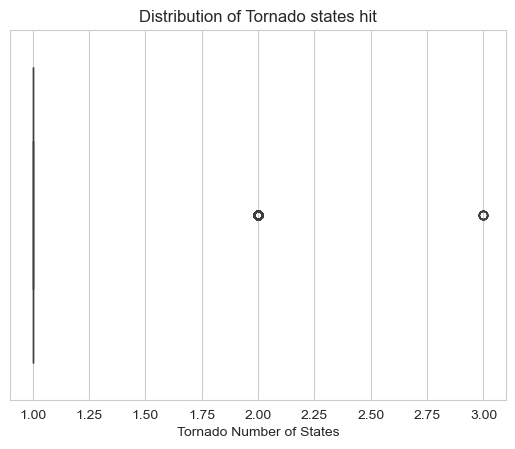

In [45]:
sns.set_style("whitegrid")
sns.boxplot(x=tornados_df['ns'])

plt.xlabel("Tornado Number of States")
plt.title("Distribution of Tornado states hit")

plt.show()

Based on the boxplot above, we can see a vast majority of the tornados remain in one state. But there are 2 outliers that are 2 states and 3 states. Although we can't know based on looking at this graph alone, it would be good to do more research into if this casued more injuries or deaths.

#### What is the distribution of variables?

To understand what datapoints will be important, its good to understand the distribution of different variables?

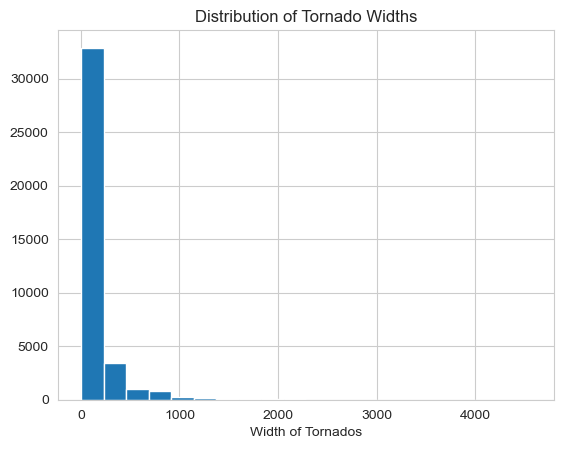

In [46]:
# Understanding the distribution of the width of a tornado
plt.hist(x=tornados_df['wid'], bins = 20)

plt.xlabel("Width of Tornados")
plt.title("Distribution of Tornado Widths")

plt.show()

Based on the above histogram, we can see a heavy right skew distribution. This indicates a vast majority of tornados are narrow. As the width of tornados increase, the amount of tornados decreases.

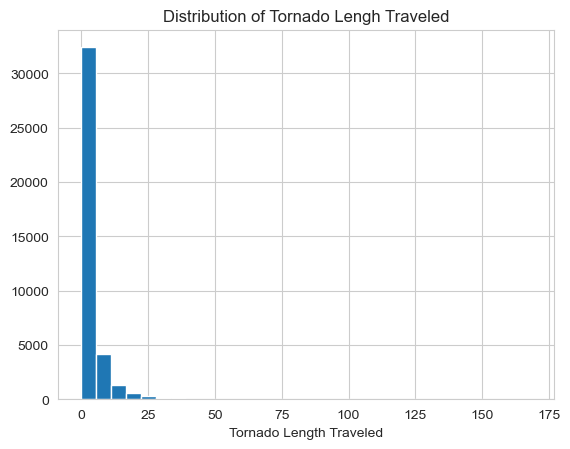

In [47]:
#Understanding the distribution of the fatalities
plt.hist(x=tornados_df['len'], bins = 30)

plt.xlabel("Tornado Length Traveled")
plt.title("Distribution of Tornado Lengh Traveled")

plt.show()

Based on the histogram above, we can see a heavy left skew. A majority fo the tornados do not travel very far. As the distance increases, the number of tornados drops.

#### Are features correlated?

To better understand which tornado characteristics are associated with injuries and fatalities, we can calculate the correlation coefficient between the number of reported injuries or fatalities, and the numerical variables in our dataset. This allows us to identify potential positive or negative relationships between tornado characteristics and their danger.

slat     -0.019907
tor_id   -0.013003
stf      -0.007539
slon      0.019430
ns        0.064416
mag       0.193334
wid       0.198224
len       0.266089
Name: inj, dtype: float64

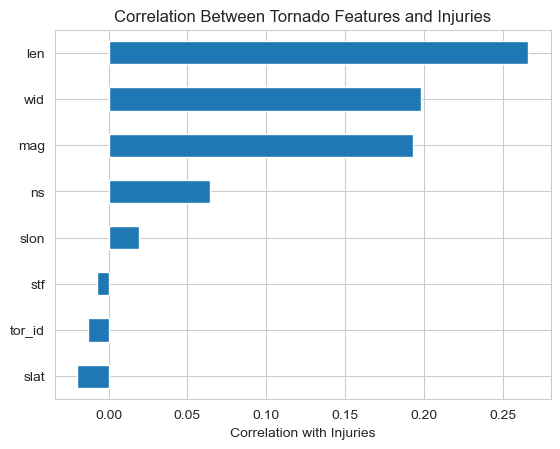

In [48]:
# Calculate correlations with tornado injuries (ignoring fatalities)
injury_correlations = tornados_df.select_dtypes(include='number').corr()['inj'].drop('inj').drop('fat')
injury_correlations = injury_correlations.sort_values()

display(injury_correlations)

# Visualize injury correlations
injury_correlations.plot(kind='barh')
plt.xlabel("Correlation with Injuries")
plt.title("Correlation Between Tornado Features and Injuries")
plt.show()

slat     -0.019379
stf      -0.012793
tor_id   -0.001155
slon      0.016064
ns        0.087115
mag       0.180062
wid       0.191941
len       0.271019
Name: fat, dtype: float64

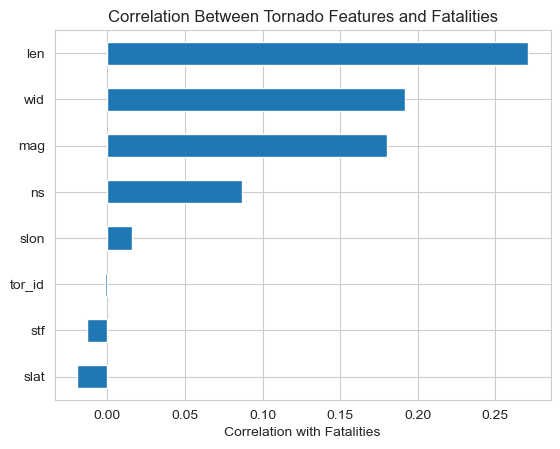

In [49]:
# Calculate correlations with tornado fatalities
fatality_correlations = tornados_df.select_dtypes(include='number').corr()['fat'].drop('fat').drop('inj')
fatality_correlations = fatality_correlations.sort_values()

display(fatality_correlations)

# Visualize fatality correlations
fatality_correlations.plot(kind='barh')
plt.xlabel("Correlation with Fatalities")
plt.title("Correlation Between Tornado Features and Fatalities")
plt.show()

From this we can see that the features with a significant correlation to both injuries and fatalities are length in miles, followed by width in yards, followed by magnitude, and finally number of states affected. The correlations are also all positive, meaning these numerical features tend to be higher in more dangerous tornados.

### 3.2 Census features and regions

Now we use tornado_census.csv, define the outcome, and look at how casualty rates vary with population density, mobile home share, year and region.

#### Casualty Rate

In [50]:
tor = pd.read_csv(DATA_DIR / "tornado_census.csv", parse_dates=["datetime"])
tor["yr"] = tor["datetime"].dt.year
tor["casualty"] = ((tor["inj"] + tor["fat"]) > 0).astype(int)

target = pd.DataFrame({
    "tornadoes": tor["casualty"].value_counts().sort_index(),
    "share (%)": (100 * tor["casualty"].value_counts(normalize=True).sort_index()).round(1)
})
target.index = ["No casualty", "Casualty"]
display(target)

,tornadoes,share (%)
No casualty,36330,92.6
Casualty,2889,7.4


In [51]:

tor = pd.read_csv(DATA_DIR / "tornado_census.csv", parse_dates=["datetime"])
tor["yr"] = tor["datetime"].dt.year
tor["casualty"] = ((tor["inj"] + tor["fat"]) > 0).astype(int)

target = pd.DataFrame({
    "tornadoes": tor["casualty"].value_counts().sort_index(),
    "share (%)": (100 * tor["casualty"].value_counts(normalize=True).sort_index()).round(1)
})
target.index = ["No casualty", "Casualty"]
display(target)

,tornadoes,share (%)
No casualty,36330,92.6
Casualty,2889,7.4


Only about 7.4% of tornadoes have a casualty, so the outcome is highly imbalanced. A model that always predicts "no casualty" would be 92.6% accurate but useless, so we do not use accuracy for model evaluation. We use PR-AUC (area under the precision-recall curve) instead, and compare it to the casualty rate as the "no-skill" baseline.

#### Population density and mobile home share

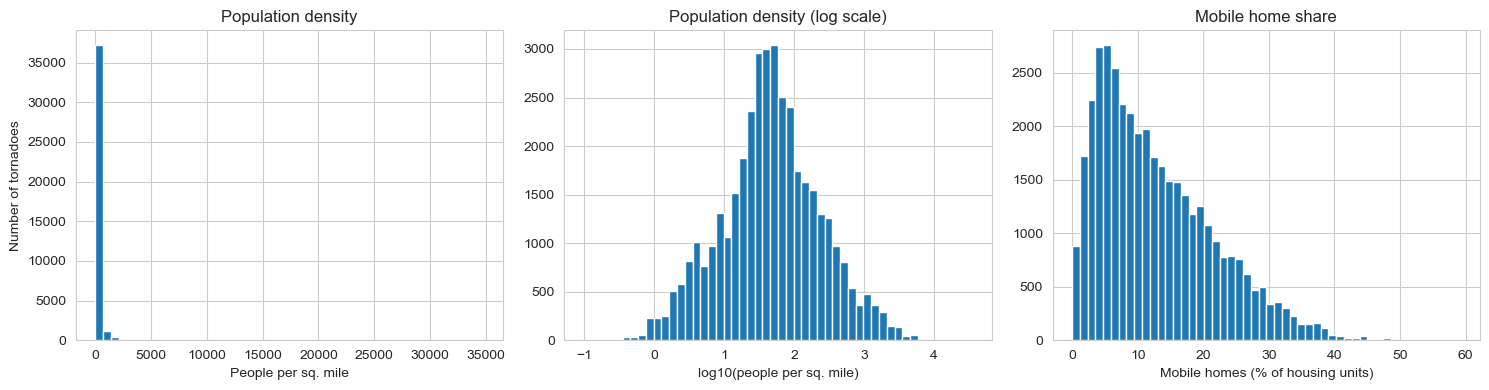

In [52]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(tor["pop_density"], bins=50)
ax[0].set(title="Population density", xlabel="People per sq. mile", ylabel="Number of tornadoes")

ax[1].hist(np.log10(tor["pop_density"]), bins=50)
ax[1].set(title="Population density (log scale)", xlabel="log10(people per sq. mile)")

ax[2].hist(tor["mobile_pct"], bins=50)
ax[2].set(title="Mobile home share", xlabel="Mobile homes (% of housing units)")

plt.tight_layout()
plt.show()

Population density is extremely right-skewed (left panel). After a log transformation it looks roughly bell-shaped (middle panel), so we use `log(population density)` in the models. Mobile home share is also right-skewed, but much less so, so we leave it on its original scale

,mean,size
density_q,,
Q1 (lowest),0.026007,9805
Q2,0.071691,9806
Q3,0.100571,9804
Q4 (highest),0.096389,9804


,mean,size
mobile_q,,
Q1 (lowest),0.057618,9806
Q2,0.060996,9804
Q3,0.079253,9804
Q4 (highest),0.096787,9805


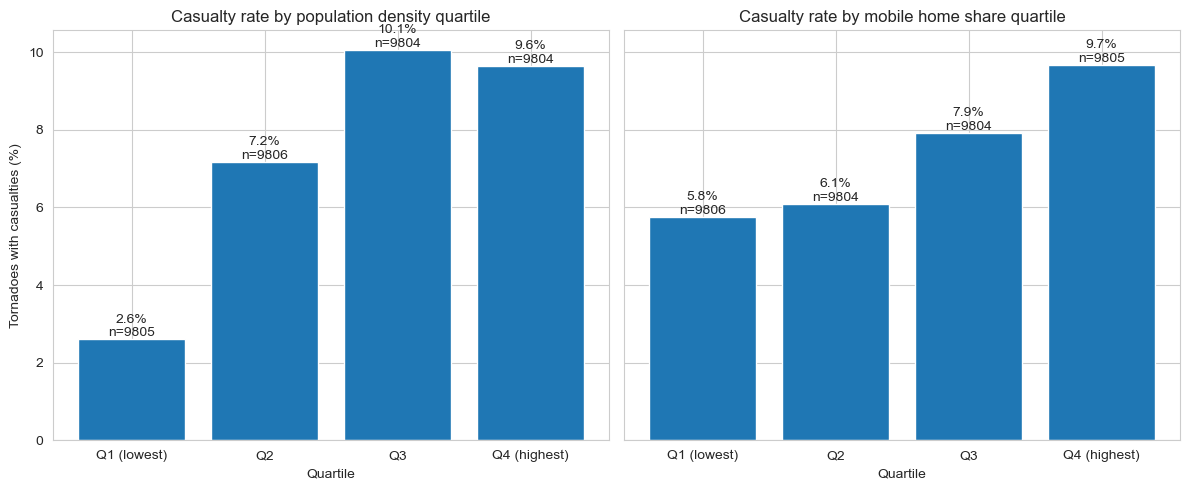

In [53]:
# Quartiles of each census feature (about 9,800 tornadoes per quartile)
q_labels = ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]
tor["density_q"] = pd.qcut(tor["pop_density"], 4, labels=q_labels)
tor["mobile_q"] = pd.qcut(tor["mobile_pct"], 4, labels=q_labels)

def rate_table(col):
    t = tor.groupby(col, observed=True)["casualty"].agg(["mean", "size"])
    t["pct"] = 100 * t["mean"]
    t["label"] = t["pct"].round(1).astype(str) + "%\nn=" + t["size"].astype(str)
    return t

dens_rate, mob_rate = rate_table("density_q"), rate_table("mobile_q")
display(dens_rate[["mean", "size"]])
display(mob_rate[["mean", "size"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for a, t, title in [(ax[0], dens_rate, "Casualty rate by population density quartile"),
                    (ax[1], mob_rate, "Casualty rate by mobile home share quartile")]:
    bars = a.bar(q_labels, t["pct"])
    a.bar_label(bars, labels=t["label"])
    a.set(title=title, xlabel="Quartile")
ax[0].set_ylabel("Tornadoes with casualties (%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "casualty_by_census_quartile.png", dpi=180)
plt.show()

* Population density: the casualty rate rises sharply from the lowest-density quartile (2.6%) to the middle quartiles (7.2%, 10.1%) and then dips slightly in the highest quartile (9.6%). So the raw pattern is not strictly monotonic.
* Mobile home share: the casualty rate increases steadily with mobile home share, from 5.8% to 9.7%.

#### Mobile home share and casualty rate over time

,mobile_pct,casualty_pct
yr,,
1995,14.1,9.4
1996,13.9,9.8
1997,14.3,10.2
1998,13.4,11.0
1999,14.2,9.6


Correlation between yearly mean mobile home share and casualty rate: 0.52


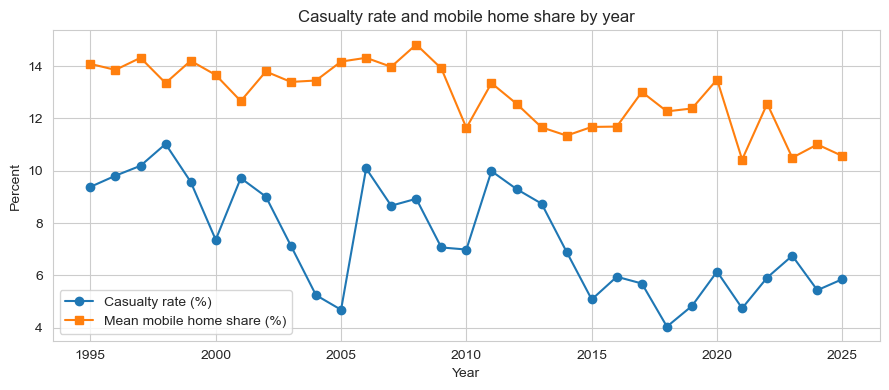

In [54]:
yearly = tor.groupby("yr").agg(mobile_pct=("mobile_pct", "mean"), casualty_pct=("casualty", "mean"))
yearly["casualty_pct"] *= 100
display(yearly.round(1).head(5))

corr = yearly["mobile_pct"].corr(yearly["casualty_pct"])
print(f"Correlation between yearly mean mobile home share and casualty rate: {corr:.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yearly.index, yearly["casualty_pct"], marker="o", label="Casualty rate (%)")
ax.plot(yearly.index, yearly["mobile_pct"], marker="s", label="Mean mobile home share (%)")
ax.set(xlabel="Year", ylabel="Percent", title="Casualty rate and mobile home share by year")
ax.legend()
plt.tight_layout()
plt.show()

Both the average mobile home share and the casualty rate decline over time (correlation about 0.52). Because both trend downward, part of this relationship may simply be a shared time trend, not a real link. We therefore include year as a control in the regression and as a feature in the models.

#### Casualty rate by region

Tornadoes with no division: 0


,mean,size
division,,
Mountain,0.021201,2547
Pacific,0.029279,444
West North Central,0.039441,10370
New England,0.059072,237
East North Central,0.074105,4777
West South Central,0.080843,8968
Middle Atlantic,0.082965,904
South Atlantic,0.100722,5540
East South Central,0.126473,5432


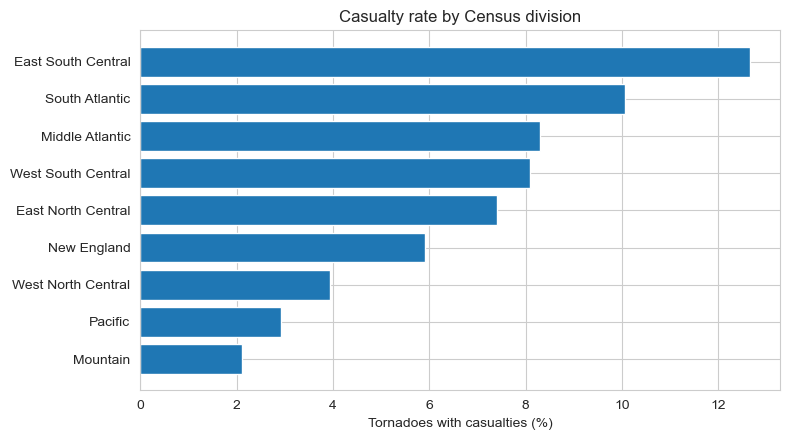

In [55]:
# U.S. Census Bureau regions and divisions
divisions = {
    "New England": ["CT", "ME", "MA", "NH", "RI", "VT"],
    "Middle Atlantic": ["NJ", "NY", "PA"],
    "East North Central": ["IL", "IN", "MI", "OH", "WI"],
    "West North Central": ["IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South Atlantic": ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV"],
    "East South Central": ["AL", "KY", "MS", "TN"],
    "West South Central": ["AR", "LA", "OK", "TX"],
    "Mountain": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY"],
    "Pacific": ["CA", "OR", "WA"],
}
div_table = pd.Series(divisions).explode().reset_index()
div_table.columns = ["division", "st"]

tor = tor.merge(div_table, on="st", how="left", validate="many_to_one")
print("Tornadoes with no division:", tor["division"].isna().sum())

div_rate = (tor.groupby("division")["casualty"].agg(["mean", "size"]).sort_values("mean"))
display(div_rate)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(div_rate.index, 100 * div_rate["mean"])
ax.set(xlabel="Tornadoes with casualties (%)", title="Casualty rate by Census division")
plt.tight_layout()
plt.show()

To compare regions we use the nine U.S. Census divisions (from the U.S. Census Bureau's regions and divisions map). Casualty rates range from 2.2% to 12.6% across divisions, so we include division as a control. As with the census quartiles, some of this may reflect differences in tornado strength between regions, which the regression addresses.

#### Casualty rate by EF rating

In [56]:
rating_rate = tor.groupby("rating")["casualty"].agg(["mean", "size"])
display(rating_rate)

,mean,size
rating,,
EF0,0.010558,21310
EF1,0.078461,12108
EF2,0.315120,3221
EF3,0.630588,850
EF4,0.852071,169
EF5,1.000000,15
EFU,0.002587,1546


Casualty rates rise steeply with EF rating. Every EF5 tornado in the data caused casualties (rate = 100%), which creates a practical problem for logistic regression.

In [57]:
tor.drop(columns=["density_q", "mobile_q"]).to_csv(DATA_DIR / "tornado_analysis.csv", index=False)

## 4. Hypothesis Testing



### 4.1 Rating group and casualties

#### Question and hypotheses

Are strong or violent tornadoes (F/EF2–5) more likely to have at least one reported injury or fatality than weak tornadoes (F/EF0–1)? This addresses the group's question about factors associated with tornado danger.

  * **H0:** rating group and occurrence of reported casualties are independent.
  * **H1:** they are associated (two-sided).
  
Use alpha = 0.05 and one primary Pearson chi-square test. The grouping and outcome are defined before computing results; this is an exploratory analysis of an existing observational dataset.


In [58]:
analysis = tor[tor["mag"].isin(range(6))].copy()
labels = ["Weak (F/EF0–1)", "Strong/violent (F/EF2–5)"]
analysis["group"] = np.where(analysis["mag"] >= 2, labels[1], labels[0])

assert analysis.tor_id.is_unique, (
    "Repeated tornado IDs would invalidate the event counts."
)
assert analysis.yr.between(1995, 2025).all()
assert analysis[["inj", "fat"]].notna().all().all()
assert (analysis[["inj", "fat"]] >= 0).all().all()

analysis["casualty"] = (analysis.inj + analysis.fat) > 0
unknown = tor[~tor["mag"].isin(range(6))]

print(f"Total records: {len(tor):,}; rated: {len(analysis):,}; unknown: {len(unknown):,}")
print(f"Unknown-rating casualty frequency: {unknown.casualty.mean():.2%}")

table = (
    pd.crosstab(analysis.group, analysis.casualty)
    .reindex(index=labels, columns=[False, True], fill_value=0)
)
table.columns = ["No reported casualty", "Reported casualty"]
display(table)

chi2, p, dof, expected = chi2_contingency(table, correction=False)
assert expected.min() >= 5, "Use an exact test if expected counts are small."

rates = table.iloc[:, 1] / table.sum(axis=1)
rr = rates.iloc[1] / rates.iloc[0]
rd = rates.iloc[1] - rates.iloc[0]
v = np.sqrt(chi2 / table.to_numpy().sum())
p_text = "< 1e-300 (smaller than floating-point precision)" if p == 0 else f"= {p:.3g}"

print(f"Chi-square = {chi2:.3f}; df = {dof}; p {p_text}; min expected count = {expected.min():.2f}")
print(f"Risk ratio = {rr:.3f}; difference = {100 * rd:.2f} percentage points; Cramer V = {v:.3f}")

Total records: 39,219; rated: 37,673; unknown: 1,546
Unknown-rating casualty frequency: 0.26%


,No reported casualty,Reported casualty
group,,
Weak (F/EF0–1),32243,1175
Strong/violent (F/EF2–5),2545,1710


Chi-square = 7177.990; df = 1; p < 1e-300 (smaller than floating-point precision); min expected count = 325.85
Risk ratio = 11.430; difference = 36.67 percentage points; Cramer V = 0.437


3,000 date-cluster bootstrap replicates; seed=602; dates=36,436
95% percentile CI for risk ratio: 10.669–12.196
95% percentile CI for difference: 35.23–38.14 percentage points


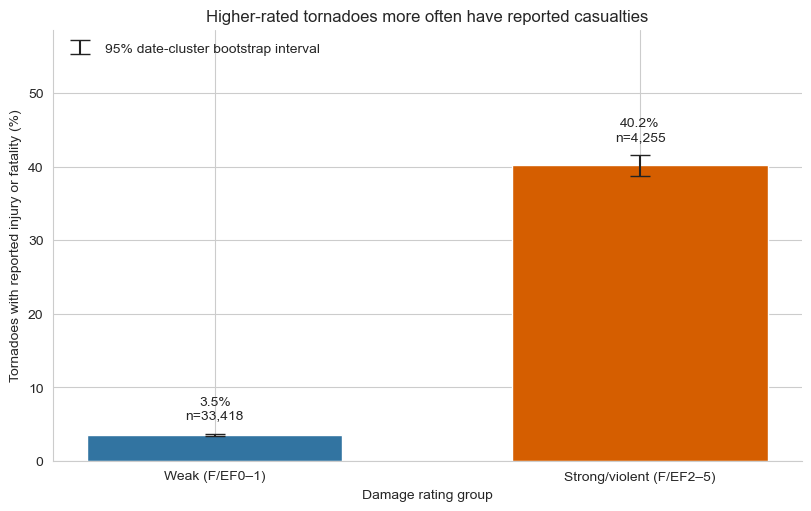

In [59]:
# Resample dates, keeping all tornadoes on each sampled date together.
# This accommodates within-date dependence, but assumes dates are independent.
analysis['strong'] = (analysis.mag >= 2).astype(int)
daily = analysis.assign(
    weak_n=1 - analysis.strong,
    strong_n=analysis.strong,
    weak_y=(1 - analysis.strong) * analysis.casualty,
    strong_y=analysis.strong * analysis.casualty
).groupby('datetime')[['weak_n', 'strong_n', 'weak_y', 'strong_y']].sum().to_numpy()

rng = np.random.default_rng(602)
boot_rates = []
for _ in range(3000):
    totals = daily[rng.integers(0, len(daily), size=len(daily))].sum(axis=0)
    boot_rates.append([totals[2] / totals[0], totals[3] / totals[1]])

boot_rates = np.asarray(boot_rates)
rate_ci = np.quantile(boot_rates, [0.025, 0.975], axis=0)
rr_ci = np.quantile(boot_rates[:, 1] / boot_rates[:, 0], [0.025, 0.975])
rd_ci = np.quantile(boot_rates[:, 1] - boot_rates[:, 0], [0.025, 0.975])

print(f'3,000 date-cluster bootstrap replicates; seed=602; dates={len(daily):,}')
print(f'95% percentile CI for risk ratio: {rr_ci[0]:.3f}–{rr_ci[1]:.3f}')
print(f'95% percentile CI for difference: {100*rd_ci[0]:.2f}–{100*rd_ci[1]:.2f} percentage points')

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
x = np.arange(2)
ax.bar(x, rates.to_numpy() * 100, color=['#3274A1', '#D55E00'], width=.6)
ax.errorbar(
    x, rates.to_numpy() * 100, 
    yerr=np.maximum(0, np.vstack([rates.to_numpy() - rate_ci[0], rate_ci[1] - rates.to_numpy()])) * 100, 
    fmt='none', color='#222222', capsize=7, label='95% date-cluster bootstrap interval'
)

for i in x:
    ax.text(i, rate_ci[1, i] * 100 + 2, f'{rates.iloc[i]:.1%}\nn={table.iloc[i].sum():,}', ha='center')

ax.set(
    xticks=x, xticklabels=labels, 
    ylabel='Tornadoes with reported injury or fatality (%)', 
    xlabel='Damage rating group', 
    title='Higher-rated tornadoes more often have reported casualties', 
    ylim=(0, min(100, rate_ci.max() * 100 + 17))
)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False)

plt.show()

In [60]:
# Descriptive sensitivity check across the F/EF transition, not extra significance tests.
analysis['era'] = np.where(pd.to_datetime(analysis.datetime) < pd.Timestamp('2007-02-01'), 'F era', 'EF era')
sensitivity = analysis.groupby(['era','group']).casualty.agg(['size','sum','mean'])
display(sensitivity.rename(columns={'size':'Tornadoes','sum':'Casualty tornadoes','mean':'Casualty proportion'}))
print(f'Conclusion: {rates.iloc[1]:.1%} of strong/violent versus {rates.iloc[0]:.1%} of weak rated tornadoes had reported casualties; RR={rr:.2f} (date-cluster 95% CI {rr_ci[0]:.2f}–{rr_ci[1]:.2f}).')
print('Reject H0 at alpha=0.05 under the chi-square independence assumption.' if p < .05 else 'Do not reject H0 at alpha=0.05.')

Tornadoes  Casualty tornadoes  \
era    group                                                     
EF era Strong/violent (F/EF2–5)       2742                1025   
       Weak (F/EF0–1)                19852                 583   
F era  Strong/violent (F/EF2–5)       1513                 685   
       Weak (F/EF0–1)                13566                 592   

                                 Casualty proportion  
era    group                                          
EF era Strong/violent (F/EF2–5)             0.373815  
       Weak (F/EF0–1)                       0.029367  
F era  Strong/violent (F/EF2–5)             0.452743  
       Weak (F/EF0–1)                       0.043639

Conclusion: 40.2% of strong/violent versus 3.5% of weak rated tornadoes had reported casualties; RR=11.43 (date-cluster 95% CI 10.67–12.20).
Reject H0 at alpha=0.05 under the chi-square independence assumption.


### 4.2 Tornado length and injuries

We test whether tornado length and injuries are positively correlated, using both Pearson and Spearman correlation, because the data are heavily skewed.

* $H_0$: $\rho \le 0$ (no positive correlation between length and injuries)
* $H_1$: $\rho > 0$ (positive correlation)

In [61]:
pair = tornados_df[["len", "inj"]].dropna()

def fmt_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.3g}"

r, p_r = pearsonr(pair["len"], pair["inj"], alternative="greater")
rho, p_s = spearmanr(pair["len"], pair["inj"], alternative="greater")

print(f"n = {len(pair):,}")
print(f"Pearson  r   = {r:.3f} (r^2 = {r**2:.3f}), one-sided p {fmt_p(p_r)}")
print(f"Spearman rho = {rho:.3f}, one-sided p {fmt_p(p_s)}")

n = 39,100
Pearson  r   = 0.266 (r^2 = 0.071), one-sided p < 1e-300
Spearman rho = 0.256, one-sided p < 1e-300


Both tests reject $H_0$ at any reasonable significance level, so there is a statistically significant positive association between path length and injuries. With almost 39,000 tornadoes, though, even a weak association would be significant, so the **effect size** matters more than the p-value. Pearson's r of about 0.27 means that length alone linearly explains only about 7% of the variation in injuries (r² = 0.07). Longer tornadoes are more dangerous on average, but length is far from the whole story. The Spearman result checks that this conclusion does not depend on a few extreme, very long tornadoes.

##### Interpretation and limits

The plotted proportions and risk ratio quantify the association; a small p-value alone does not measure practical importance. The chi-square p-value treats tornadoes as independent, which can be violated during outbreaks. The date-cluster bootstrap intervals provide a sensitivity check for same-day dependence, but do not account for dependence across dates or all regional differences. The era table checks whether the direction persists across the rating-system change, without claiming confounding is eliminated.

This is an association in recorded events, not evidence that the assigned rating causes casualties. Population exposure, region, warning availability, time of day, reporting practices and storm characteristics may affect both variables. Ratings themselves depend on observed damage and exposure. Unknown ratings may be systematically different; the conclusion applies to rated tornadoes, not automatically to all tornadoes. Zero reported casualties means zero in this database, not proof that no harm occurred. The 2025 records should be treated as potentially provisional.

For later modeling, this result supports examining rating as a descriptive correlate of danger. A post-event damage rating could leak outcome-related information into a model intended to predict risk before a tornado occurs.

### 4.3 Census variables and casualties, controlling for tornado characteristics


In [62]:
model_df = pd.read_csv(DATA_DIR / "tornado_analysis.csv", parse_dates=["datetime"])

model_df["log_len"] = np.log(model_df["len"])
model_df["log_wid"] = np.log(model_df["wid"])
model_df["log_density"] = np.log(model_df["pop_density"])
model_df["yr_c"] = model_df["yr"] - 2010
model_df["rating4"] = model_df["rating"].replace({"EF4": "EF4+", "EF5": "EF4+"})

n_all = len(model_df)
model_df = model_df.dropna(subset=["log_len", "log_wid"]).reset_index(drop=True)
print(f"Tornadoes: {n_all:,}; used in models (valid length and width): {len(model_df):,}")

Tornadoes: 39,219; used in models (valid length and width): 38,666


In [63]:
base = "casualty ~ C(rating4, Treatment('EF0')) + log_len + log_wid + yr_c + C(division)"
full_formula = base + " + log_density + mobile_pct"

restricted = smf.logit(base, data=model_df).fit(disp=0)
full = smf.logit(full_formula, data=model_df).fit(disp=0)

lr_stat = 2 * (full.llf - restricted.llf)
dof_diff = full.df_model - restricted.df_model
p_lr = stats.chi2.sf(lr_stat, dof_diff)
print(f"LR statistic = {lr_stat:.1f}, df = {dof_diff:.0f}, p-value = {p_lr:.3g}")

LR statistic = 292.5, df = 2, p-value = 3.11e-64


In [74]:
# Odds ratios of the full model
odds = np.exp(full.conf_int())
odds.columns = ["ci_low", "ci_high"]
odds["odds_ratio"] = np.exp(full.params)
odds["p_value"] = full.pvalues
display(odds.round(3))



,ci_low,ci_high,odds_ratio,p_value
Intercept,0.001,0.001,0.001,0.000
"C(rating4, Treatment('EF0'))[T.EF1]",4.469,6.175,5.253,0.000
"C(rating4, Treatment('EF0'))[T.EF2]",19.280,27.852,23.173,0.000
"C(rating4, Treatment('EF0'))[T.EF3]",60.544,98.331,77.158,0.000
"C(rating4, Treatment('EF0'))[T.EF4+]",155.904,413.338,253.852,0.000
"C(rating4, Treatment('EF0'))[T.EFU]",0.277,2.033,0.751,0.573
C(division)[T.East South Central],0.928,1.307,1.101,0.271
C(division)[T.Middle Atlantic],0.615,1.116,0.829,0.217
C(division)[T.Mountain],0.964,1.884,1.348,0.081
C(division)[T.New England],0.440,1.534,0.822,0.537


Since the p-value of LR test is very small (p < 0.001), we reject $H_0$
. The full model explains the data better than the restricted model.
Even after controlling for rating, size, year, and division, tornadoes in counties with higher population density and a higher mobile home share are more likely to have casualties.
Odds ratios: 1.30 for doubling density, 1.34 for a 10 percentage point higher mobile home share

## 5. Predicting Casualties

Goal: predict whether a tornado causes casualties, and compare which features the models rely on.

* Target: casualty (1 if injuries + fatalities > 0)
* Features: rating (EF0-EF3, EF4+, EFU), log(length), log(width), log(population density), mobile home share, year, census division
* Models: logistic regression, random forest, LightGBM
* Split by time: tornadoes on the same day are not independent and the casualty rate has declined over time, so a random split would leak information. We train on 1995-2018 and test on 2019-2025.
* Tuning: expanding-window cross-validation inside the training period (three validation periods: 2007-2010, 2011-2014, 2015-2018).
* Metric: PR-AUC (average precision), with ROC-AUC as a secondary metric.

In [75]:
num_cols = ["log_len", "log_wid", "log_density", "mobile_pct", "yr"]
cat_cols = ["rating4", "division"]

# we want to split the training and the testing by year
train = model_df[model_df["yr"] <= 2018].reset_index(drop=True)
test = model_df[model_df["yr"] >= 2019].reset_index(drop=True)
y_train, y_test = train["casualty"], test["casualty"]
print(f"Train: {len(train):,} tornadoes ({y_train.mean():.1%} casualty) | "
      f"Test: {len(test):,} tornadoes ({y_test.mean():.1%} casualty)")

X_train = pd.get_dummies(train[num_cols + cat_cols], columns=cat_cols, drop_first=True, dtype=float)
X_test = pd.get_dummies(test[num_cols + cat_cols], columns = cat_cols, drop_first=True, dtype=float)  

# LightGMB
X_train_gbm = train[num_cols + cat_cols].astype({"rating4": "category", "division": "category"})
X_test_gbm = test[num_cols + cat_cols].astype({"rating4": "category", "division": "category"})
print(X_train.shape, X_test.shape)

Train: 29,047 tornadoes (8.0% casualty) | Test: 9,619 tornadoes (5.6% casualty)
(29047, 18) (9619, 18)


In [76]:

# Folds for GridSearchCV

# Fold 1: train 1995-2006, validate 2007-2010
fold1_train = train.index[train["yr"] <= 2006]
fold1_val = train.index[train["yr"].between(2007, 2010)]

# Fold 2: train 1995-2010, validate 2011-2014
fold2_train = train.index[train["yr"]<= 2010]
fold2_val = train.index[train["yr"].between(2011, 2014)]

# Fold 3: train 1995-2014, validate 2015-2018
fold3_train = train.index[train["yr"] <= 2014]
fold3_val = train.index[train["yr"].between(2015, 2018)]

folds = [(fold1_train, fold1_val),
         (fold2_train, fold2_val),
         (fold3_train, fold3_val)]


### 5.1 Model training and cross-validation

In [78]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000))
logit_cv = cross_val_score(logit, X_train, y_train, cv=folds, scoring ="average_precision")
print(f"Logistic regression CV PR-AUC:, {logit_cv}, {logit_cv.mean():.3f}")

logit.fit(X_train, y_train)

Logistic regression CV PR-AUC:, [0.53446918 0.56942119 0.43178516], 0.512


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

In [79]:
# Random Forest

rf_search = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    param_grid={"min_samples_leaf": [5, 20, 50],
                "max_features": ["sqrt", 0.5]},
    cv=folds, scoring ="average_precision"
    )
rf_search.fit(X_train, y_train)

print(f"Random forest best: {rf_search.best_params_}, {rf_search.best_score_:.3f}")

Random forest best: {'max_features': 'sqrt', 'min_samples_leaf': 20}, 0.504


In [80]:
# LightGBM

gbm_search = GridSearchCV(
    LGBMClassifier(learning_rate=0.05, random_state=42, verbose=-1),
    param_grid={"num_leaves": [3, 5, 7],
                "min_child_samples": [200, 300, 400],
                "n_estimators": [200, 300, 400]},
    cv=folds, scoring ="average_precision"
)
gbm_search.fit(X_train_gbm, y_train)
print(f"LightGBM best: {gbm_search.best_params_}, {gbm_search.best_score_:.3f}")


LightGBM best: {'min_child_samples': 300, 'n_estimators': 300, 'num_leaves': 3}, 0.512


In [81]:
# CV Tables

rf_cv = pd.DataFrame(rf_search.cv_results_).loc[rf_search.best_index_]
rf_cv

gbm_cv = pd.DataFrame(gbm_search.cv_results_).loc[gbm_search.best_index_]
gbm_cv

cv_table = pd.DataFrame({
    "Logistic Regression": logit_cv,
    "Random Forest": rf_cv[["split0_test_score", "split1_test_score", "split2_test_score"]].values,
    "LightGBM": gbm_cv[["split0_test_score", "split1_test_score", "split2_test_score"]].values,
}, index=["Split 1: 2007-2010", "Split 2: 2011-2014", "Split 3: 2015-2018"])

cv_table.loc["Mean"] = cv_table.mean()
display(cv_table.astype(float).round(3))

,Logistic Regression,Random Forest,LightGBM
Split 1: 2007-2010,0.534,0.512,0.519
Split 2: 2011-2014,0.569,0.575,0.582
Split 3: 2015-2018,0.432,0.425,0.434
Mean,0.512,0.504,0.512


The mean cross-validated PR-AUC is almost the same for the three models (0.504-0.512). Differences between validation periods (0.43-0.58) are much larger than differences between models, and the best model changes from period to period, so the three models perform about equally well. All models score lower in 2015-2018 because casualties were rarer in that period (5.2%, compared with 8-9% in earlier periods), and PR-AUC depends on how common the positive class is.

### 5.2 Test-period performance

In [82]:
# test
p_logit = logit.predict_proba(X_test)[:,1]
p_rf = rf_search.predict_proba(X_test)[:, 1]
p_gbm = gbm_search.predict_proba(X_test_gbm)[:, 1]

# PR-AUC
pr_logit = average_precision_score(y_test, p_logit)
pr_rf = average_precision_score(y_test, p_rf)
pr_gbm = average_precision_score(y_test, p_gbm)

#ROC-AUC
roc_logit = roc_auc_score(y_test, p_logit)
roc_rf = roc_auc_score(y_test, p_rf)
roc_gbm = roc_auc_score(y_test, p_gbm)

results = pd.DataFrame({
    "PR-AUC": [pr_logit, pr_rf, pr_gbm],
    "ROC-AUC": [roc_logit, roc_rf, roc_gbm]
}, index = ["Logistic Regression", "Random Forest", "LightGBM"])

display(results.round(3))

,PR-AUC,ROC-AUC
Logistic Regression,0.477,0.879
Random Forest,0.494,0.880
LightGBM,0.487,0.880


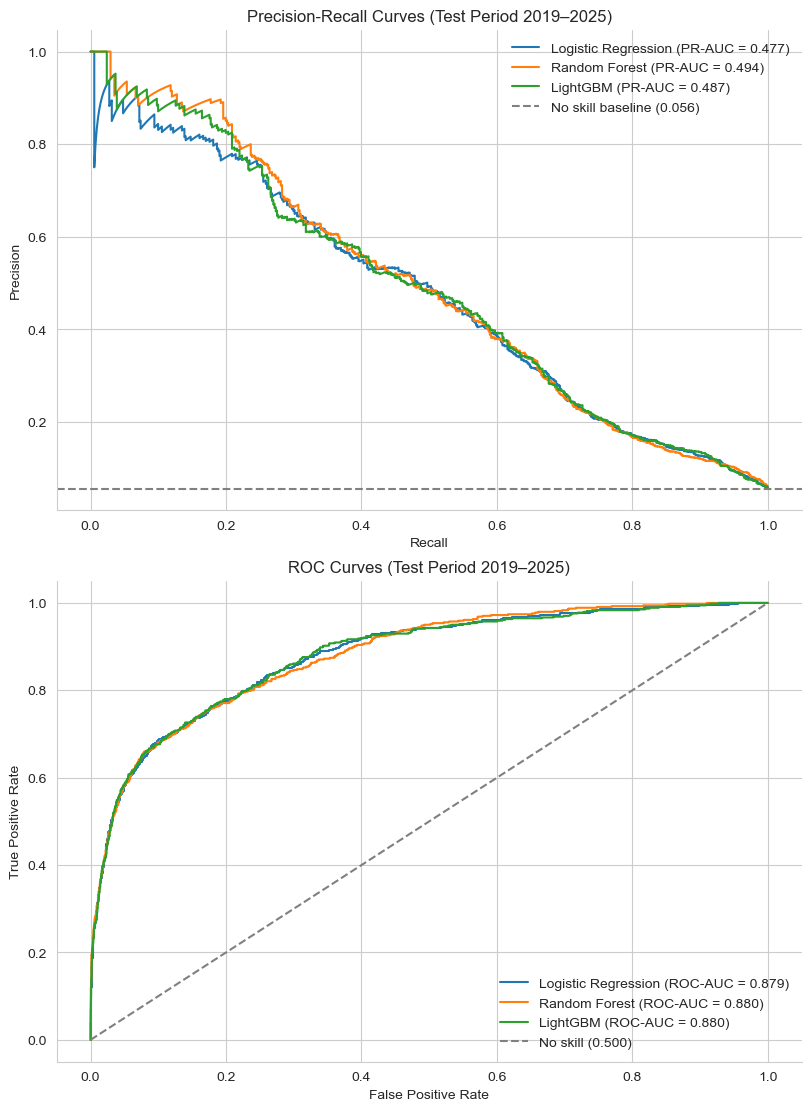

In [88]:
preds = {
    "Logistic Regression": p_logit,
    "Random Forest": p_rf,
    "LightGBM": p_gbm,
}
baseline = y_test.mean()

fig, axes = plt.subplots(2, 1, figsize=(8, 11), constrained_layout=True)


for name, p in preds.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    pr_auc = average_precision_score(y_test, p)
    axes[0].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.3f})")

axes[0].axhline(
    baseline, color="gray", linestyle="--", 
    label=f"No skill baseline ({baseline:.3f})"
)
axes[0].set(
    xlabel="Recall", 
    ylabel="Precision", 
    title="Precision-Recall Curves (Test Period 2019–2025)"
)
axes[0].legend(loc="upper right", frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

for name, p in preds.items():
    fpr, tpr, _ = sklearn.metrics.roc_curve(y_test, p)
    roc_auc = roc_auc_score(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC-AUC = {roc_auc:.3f})")

axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="No skill (0.500)")
axes[1].set(
    xlabel="False Positive Rate", 
    ylabel="True Positive Rate", 
    title="ROC Curves (Test Period 2019–2025)"
)
axes[1].legend(loc="lower right", frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)
plt.show()

On the test period (2019-2025) the three models again perform similarly (PR-AUC 0.477-0.494, ROC-AUC about 0.88). Their PR-AUC is roughly 8.5 times the no-skill baseline of 0.056. The model ranking differs from cross-validation (random forest was lowest in cross-validation but highest on the test period), which confirms that the differences between models are small.

### Do the census features improve prediction?

The likelihood ratio test shows the census variables are *associated* with casualties after controlling for other factors. Here we ask a different, practical question: do they improve out-of-sample *prediction*? We refit the same logistic regression with feature groups added step by step, and compare cross-validated and test performance.

In [89]:
rating_cols = [c for c in X_train.columns if c.startswith("rating4_")]
div_cols = [c for c in X_train.columns if c.startswith("division_")]

feature_sets = {
    "1. Rating + size":                    rating_cols + ["log_len", "log_wid"],
    "2. + year + division":                rating_cols + ["log_len", "log_wid", "yr"] + div_cols,
    "3. + census (density, mobile homes)": list(X_train.columns),
}

rows = []
for name, cols in feature_sets.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    cv = cross_val_score(m, X_train[cols], y_train, cv=folds, scoring="average_precision")
    m.fit(X_train[cols], y_train)
    p = m.predict_proba(X_test[cols])[:, 1]
    rows.append({"Feature set": name, "CV PR-AUC": cv.mean(),
                 "Test PR-AUC": average_precision_score(y_test, p),
                 "Test ROC-AUC": roc_auc_score(y_test, p)})
ablation = pd.DataFrame(rows).set_index("Feature set")
display(ablation.round(3))

gain = ablation["Test PR-AUC"].iloc[2] - ablation["Test PR-AUC"].iloc[1]
print(f"Adding the census features changes test PR-AUC by {gain:+.3f} "
      f"({ablation['Test PR-AUC'].iloc[1]:.3f} -> {ablation['Test PR-AUC'].iloc[2]:.3f}).")

,CV PR-AUC,Test PR-AUC,Test ROC-AUC
Feature set,,,
1. Rating + size,0.479,0.471,0.865
2. + year + division,0.499,0.469,0.875
"3. + census (density, mobile homes)",0.512,0.477,0.879


Adding the census features changes test PR-AUC by +0.009 (0.469 -> 0.477).


Read the table from top to bottom: each row adds a feature group. If the census rows improve PR-AUC only slightly, that does not contradict the LRT. A variable can be statistically significant in a large sample and still add modest predictive power once rating and size are known.

### Which features do the models use?

We use permutation importance on the test set with the tuned LightGBM model: each feature is randomly shuffled several times, and we measure how much PR-AUC drops. A larger drop means the model relies more on that feature.

,Importance (mean),Importance (std)
rating4,0.375,0.009
log_density,0.053,0.006
log_len,0.053,0.006
mobile_pct,0.018,0.003
log_wid,0.000,0.002
division,0.000,0.002
yr,0.000,0.000


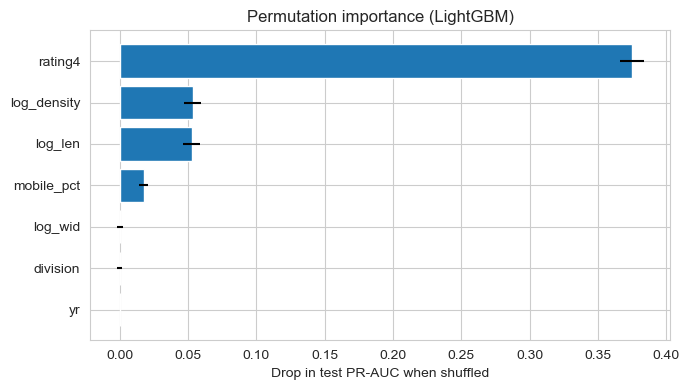

In [90]:
imp = permutation_importance(gbm_search.best_estimator_, X_test_gbm, y_test,
                             scoring="average_precision", n_repeats=10, random_state=SEED)
imp_table = (pd.DataFrame({"Importance (mean)": imp.importances_mean,
                           "Importance (std)": imp.importances_std},
                          index=num_cols + cat_cols)
               .sort_values("Importance (mean)", ascending=False))
display(imp_table.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
t = imp_table.iloc[::-1]
ax.barh(t.index, t["Importance (mean)"], xerr=t["Importance (std)"])
ax.set(xlabel="Drop in test PR-AUC when shuffled", title="Permutation importance (LightGBM)")
plt.tight_layout()
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=180)
plt.show()

* The EF rating is by far the most important feature (PR-AUC drops by about 0.375 when it is shuffled), followed by population density and length (about 0.053 each).
* Mobile home share has a small importance (0.018), but it is much larger than its standard deviation (0.003), so it still contributes to the predictions.

## 6. Conclusions
* Whether a tornado causes casualties mostly depends on its EF rating and size (length).
* For tornadoes with the same rating and size, those passing through densely populated areas with a high mobile home share are more likely to cause casualties.
* We expected nonlinear relationships or interactions, but the tree-based models (random forest and LightGBM) show almost the same results as logistic regression. This suggests that the relationships between features and casualty risk are mostly simple and additive.


## 7. Limitations
* Tornado length, width, and EF rating are determined after a tornado occurs, so our models cannot forecast casualties before a tornado.
* The census variables (population density and mobile home share) are county-level values, so they may differ from the data along a tornado's actual path.
* We used 2000 Census data for 1995-2008 tornadoes, because ACS 5-year estimates for counties are not available before 2009.
* Our results show associations, not causal relationships.  

## Sources

- [SPC database documentation](https://www.spc.noaa.gov/wcm/data/SPC_severe_database_description.pdf) and repository codebook for event segments, casualty counts and rating definitions.
- [SciPy Pearson chi-square documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).
- [Gazette Census Files](https://www.census.gov/geographies/reference-files/time-series/geo/gazetteer-files.html) county area data
- [County Changes](https://www.census.gov/programs-surveys/geography/technical-documentation/county-changes.html)
- [Census regions and divisions](https://www.nist.gov/system/files/documents/2025/08/11/MAP_Census%20Regions%20and%20Divisions%20of%20the%20USA.pdf)
- [Logistic Regression information](https://scikit-learn.org/1.6/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [StandardScaler](https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Pipelines](https://scikit-learn.org/1.6/modules/generated/sklearn.pipeline.Pipeline.html)